# 01 · Validation of the Geant4 11 port

**Question:** after porting JEPO-1.1 from Geant4 10 to Geant4 11.4.3 and making the bar geometry configurable, does the simulation still reproduce the original code and the results quoted in the paper?

Data (all in `~/runs`, 100k events per run, fixed seeds `1000 + k`):

| directory | code | Geant4 | setup |
|---|---|---|---|
| `base_theta`, `base_tb` | original (port only) | 11.4.3 | theta scan, 2018 test beam |
| `new_theta`, `new_tb` | parametrised (`cf372b0`) | 11.4.3 | same |
| `repro_a`, `repro_b` | parametrised, fixed `beam.in` reading | 11.4.3 | test beam, twice |
| `g4107_0.22`, `g4107_0.0` | original | 10.7.4 | test beam, smearing 0.22 and 0 |

The analysis is `analysis/sith_reco.py`, a Python port of `Simulation_runner.cpp` + `Peak_fitter.py`: on the same files it gives the same numbers as the original ROOT scripts (theta: 0.08663° vs 0.0866°; test beam: 1.3028 vs 1.303 mm).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sithplot as sp
sp.setup()
import sith_reco as sr
from compare_ntuples import load as load_events
R = sp.RUNS
geom = sr.Geometry()
pat = lambda d: str(R / d / "output" / "*MeV_t*-{run}.root")
PAPER = dict(sigma_tb_mm=0.911, sigma_tb_data_mm=0.907, sigma_theta_deg=0.0912)

## 1. Event-by-event reproducibility

With a fixed seed, multi-threaded Geant4 generates every event identically, whichever thread processes it. The comparison is done by `eventID`, column by column.

In [2]:
def identical(a, b, run):
    A, B = load_events(str(R / a), run), load_events(str(R / b), run)
    return all(np.array_equal(A[k], B[k], equal_nan=True) for k in A)

checks = [("theta scan: original vs parametrised", "base_theta", "new_theta", [0, 12, 25]),
          ("test beam: original, two runs with the same seed", "base_tb", "base_tb2", [3]),
          ("test beam: parametrised + fixed beam.in, two runs", "repro_a", "repro_b", [0, 3, 6])]
rows = [dict(comparison=c, runs=str(runs), identical=all(identical(a, b, r) for r in runs)) for c, a, b, runs in checks]
pd.DataFrame(rows)

,comparison,runs,identical
0,theta scan: original vs parametrised,"[0, 12, 25]",True
1,"test beam: original, two runs with the same seed",[3],False
2,"test beam: parametrised + fixed beam.in, two runs","[0, 3, 6]",True


With the default geometry the parametrised code is **bit-identical** to the original. The original test beam, instead, was *not* reproducible: each thread read `beam.in` line by line, so the line used by an event depended on which thread had processed event 0. Now `beam.in` is read once and indexed by `eventID`.

## 2. Theta scan (full detector, PERPENDICULAR configuration)

26 runs at fixed theta from 5° to 17.5°, uniform phi. The reconstructed-theta distribution is the `HTh` histogram of `Simulation_runner.cpp` (0.05° bins).

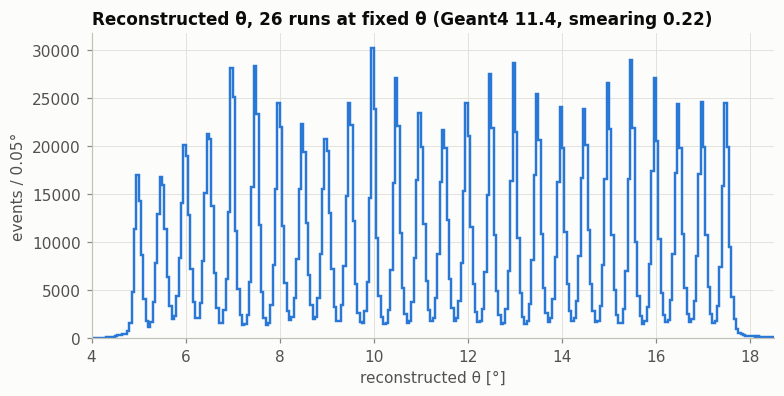

In [3]:
th = sr.analyse_theta(pat("base_theta"), 26, geom)
per_run = pd.DataFrame(th["per_run"])
all_theta, phi_rows = [], []
for k in range(26):
    F, B, gen = sr.load(sr.run_files(pat("base_theta"), k), geom)
    rec = sr.reconstruct(F, B, geom)
    all_theta.append(rec["theta"])
    d = (rec["phi"] - np.degrees(gen["phi_lab"]) + 180) % 360 - 180      # azimuthal residual
    d = d[np.isfinite(d)]
    s0 = 1.4826 * np.median(np.abs(d - np.median(d)))
    p, e, _, _ = sr.fit_peak(d, np.median(d), s0, half_width=5 * s0, bins=200,
                             rng=(np.median(d) - 6 * s0, np.median(d) + 6 * s0))
    phi_rows.append(dict(theta_gen=sr.THETA_ARRAY[k], sigma_phi=abs(p[2]), sigma_phi_err=e[2]))
all_theta = np.concatenate(all_theta)
phi_runs = pd.DataFrame(phi_rows)

fig, ax = plt.subplots(figsize=(8, 3.6))
sp.hist_line(ax, all_theta, 400, (0, 20), sp.SERIES[0])
ax.set(xlim=(4, 18.5), xlabel="reconstructed θ [°]", ylabel="events / 0.05°",
       title="Reconstructed θ, 26 runs at fixed θ (Geant4 11.4, smearing 0.22)")
plt.show()

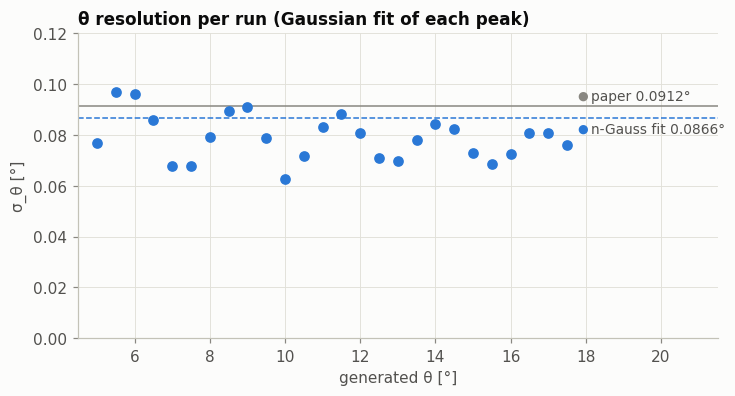

n-Gaussian fit (Peak_fitter.py procedure): 0.0866 ± 0.0002°  (χ²/ndf 251);  mean of the per-run fits: 0.0790°


In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.errorbar(per_run.theta_gen, per_run.sigma, per_run.sigma_err, fmt="o", color=sp.SERIES[0], ms=6)
ax.axhline(th["multi_sigma_mean"], color=sp.SERIES[0], lw=1, ls="--")
ax.axhline(PAPER["sigma_theta_deg"], color=sp.MUTED, lw=1)
sp.end_label(ax, 17.6, th["multi_sigma_mean"], f"n-Gauss fit {th['multi_sigma_mean']:.4f}°", sp.SERIES[0], dy=-7)
sp.end_label(ax, 17.6, PAPER["sigma_theta_deg"], "paper 0.0912°", sp.MUTED, dy=7)
ax.set(xlim=(4.5, 21.5), ylim=(0, 0.12), xlabel="generated θ [°]", ylabel="σ_θ [°]",
       title="θ resolution per run (Gaussian fit of each peak)")
plt.show()
print(f"n-Gaussian fit (Peak_fitter.py procedure): {th['multi_sigma_mean']:.4f} ± {th['multi_sigma_err_mean']:.4f}°  "
      f"(χ²/ndf {th['multi_chi2ndf']:.0f});  mean of the per-run fits: {th['sigma_mean']:.4f}°")

The n-Gaussian fit of the same histogram (the paper's procedure) gives **0.0866°** against 0.0912° in the paper: 5% lower. The very large χ²/ndf shows that the peaks are not Gaussian (tails) and that the 0.05° bins are wide compared with σ (the aliasing is visible in the peak heights), so the number depends on the procedure; the difference with the paper may come from a different version of `Simulation_runner.cpp` (the last commit, "angular correction", is dated 28/10/2021).

### Azimuthal angle

The same runs have uniform phi, so the azimuthal residual φ_rec − φ_generated is available too. Its width scales as 1/r, i.e. as cot θ; the paper quotes σ_φ = (0.057 ± 0.007)·cot θ °, obtained from dedicated fixed-phi scans.

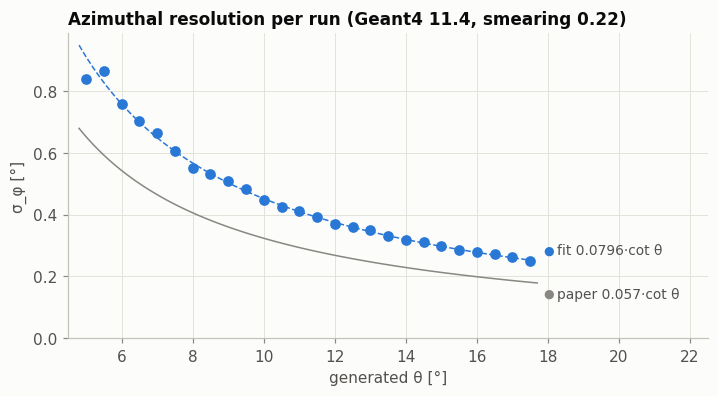

σ_φ = 0.0796·cot θ °  (paper: 0.057 ± 0.007, from fixed-phi scans)


In [5]:
cot = 1 / np.tan(np.radians(phi_runs.theta_gen))
w = 1 / phi_runs.sigma_phi_err ** 2
A = np.sum(w * phi_runs.sigma_phi * cot) / np.sum(w * cot ** 2)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.errorbar(phi_runs.theta_gen, phi_runs.sigma_phi, phi_runs.sigma_phi_err, fmt="o", color=sp.SERIES[0], ms=6)
tt = np.linspace(4.8, 17.7, 100)
ax.plot(tt, A / np.tan(np.radians(tt)), color=sp.SERIES[0], lw=1, ls="--")
ax.plot(tt, 0.057 / np.tan(np.radians(tt)), color=sp.MUTED, lw=1)
sp.end_label(ax, 17.7, A / np.tan(np.radians(17.7)), f"fit {A:.4f}·cot θ", sp.SERIES[0], dy=7)
sp.end_label(ax, 17.7, 0.057 / np.tan(np.radians(17.7)), "paper 0.057·cot θ", sp.MUTED, dy=-7)
ax.set(xlim=(4.5, 22.5), ylim=(0, None), xlabel="generated θ [°]", ylabel="σ_φ [°]",
       title="Azimuthal resolution per run (Geant4 11.4, smearing 0.22)")
plt.show()
print(f"σ_φ = {A:.4f}·cot θ °  (paper: 0.057 ± 0.007, from fixed-phi scans)")

## 3. 2018 test beam (PARALLEL configuration)

Two parallel layers of 3 modules; the back layer is moved in 7 steps (~4.78 mm). The *offset* is η_F − η_B for the module pair (3, 11); its width, calibrated in mm with the distance between the first and the last peak, is the quoted resolution.

Step 0 is not Gaussian: there the beam hits the back layer across two module pairs ((3,11) and (3,10), about 60/40), and the right-hand tail comes from the events of the second pair. This is a feature of the setup, also present in the original code.

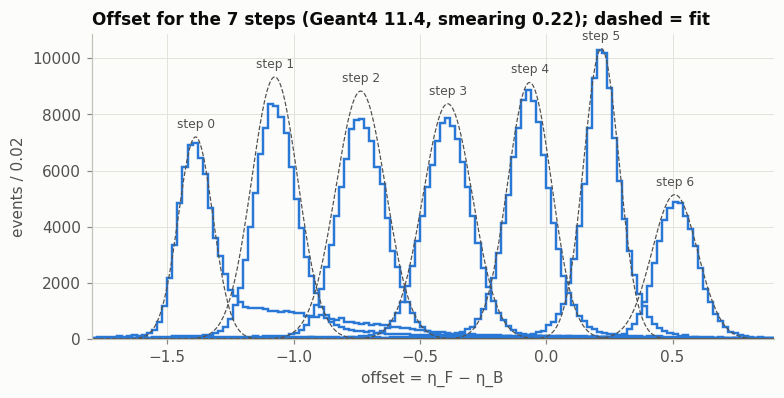

In [6]:
def tb_offsets(d):
    out = []
    for k in range(7):
        F, B, _ = sr.load(sr.run_files(pat(d), k), geom, extra=())
        qF, rF, eF = sr.select_pairs(F, 7); qB, rB, eB = sr.select_pairs(B, 7)
        m = (qF == 3) & (rF == 11) & (qB >= 0)
        out.append(eF[m] - eB[m])
    return out

tb11, tb107 = sr.analyse_tb(pat("repro_a"), 7, geom), sr.analyse_tb(pat("g4107_0.22"), 7, geom)
offs = tb_offsets("repro_a")
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.linspace(-2, 2, 800)
for k, o in enumerate(offs):
    sp.hist_line(ax, o, 200, (-2, 2), sp.SERIES[0])
    s = tb11["sigma_mm"][k] / tb11["calib_mm_per_offset"]; mu = tb11["means"][k]; a = tb11["amplitudes"][k]
    ax.plot(x, a * np.exp(-0.5 * ((x - mu) / s) ** 2), color=sp.INK2, lw=0.8, ls="--")
    ax.annotate(f"step {k}", (mu, max(a, np.histogram(o, 200, (-2, 2))[0].max())), xytext=(0, 6),
                textcoords="offset points", ha="center", color=sp.INK2, fontsize=8)
ax.set(xlim=(-1.8, 0.9), xlabel="offset = η_F − η_B", ylabel="events / 0.02",
       title="Offset for the 7 steps (Geant4 11.4, smearing 0.22); dashed = fit")
plt.show()

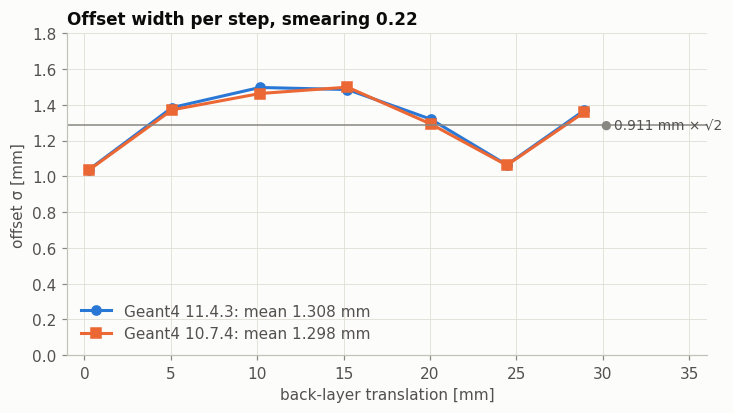

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
xs = np.array(sr.TB_TRANSLATE)
for res, lab, c, mk in ((tb11, "Geant4 11.4.3", sp.SERIES[0], "o"), (tb107, "Geant4 10.7.4", sp.SERIES[1], "s")):
    ax.plot(xs, res["sigma_mm"], marker=mk, color=c, label=f"{lab}: mean {res['sigma_mm_mean']:.3f} mm")
ref = PAPER["sigma_tb_mm"] * np.sqrt(2)
ax.axhline(ref, color=sp.MUTED, lw=1)
sp.end_label(ax, 29.5, ref, "0.911 mm × √2", sp.MUTED)
ax.set(xlim=(-1, 36), ylim=(0, 1.8), xlabel="back-layer translation [mm]",
       ylabel="offset σ [mm]", title="Offset width per step, smearing 0.22")
ax.legend(loc="lower left")
plt.show()

In [8]:
rows = []
for lab, d in (("Geant4 11.4.3, smearing 0.22", "repro_a"), ("Geant4 10.7.4, smearing 0.22", "g4107_0.22"),
               ("Geant4 11.4.3, smearing 0", "const_0.0"), ("Geant4 10.7.4, smearing 0", "g4107_0.0")):
    r = sr.analyse_tb(pat(d), 7, geom)
    rows.append({"simulation": lab, "offset σ [mm]": round(r["sigma_mm_mean"], 3),
                 "± [mm]": round(r["sigma_mm_err_mean"], 3), "σ / √2 [mm]": round(r["sigma_mm_mean"] / np.sqrt(2), 3)})
rows.append({"simulation": "paper: G4 (dE = 0.22)", "offset σ [mm]": None, "± [mm]": 0.003, "σ / √2 [mm]": None,
             "quoted value [mm]": 0.911})
rows.append({"simulation": "paper: 2018 TB data", "offset σ [mm]": None, "± [mm]": 0.003, "σ / √2 [mm]": None,
             "quoted value [mm]": 0.907})
pd.DataFrame(rows)

,simulation,offset σ [mm],± [mm],σ / √2 [mm],quoted value [mm]
0,"Geant4 11.4.3, smearing 0.22",1.308,0.008,0.925,NaN
1,"Geant4 10.7.4, smearing 0.22",1.298,0.008,0.918,NaN
2,"Geant4 11.4.3, smearing 0",0.795,0.002,0.562,NaN
3,"Geant4 10.7.4, smearing 0",0.768,0.002,0.543,NaN
4,paper: G4 (dE = 0.22),NaN,0.003,NaN,0.911
5,paper: 2018 TB data,NaN,0.003,NaN,0.907


**Reading.**

* The Geant4 version does not matter: 10.7.4 and 11.4.3 differ by less than 3% (also with smearing 0, i.e. physics only).
* With smearing 0.22 the offset width is ~1.30 mm; divided by √2 it gives ~0.92 mm, within ~1% of the 0.911 in the paper. `Peak_fitter.py` reports the full width, so the paper value looks like the **per-layer** resolution (offset / √2): this should be stated explicitly in the text, for both G4 and data.
* The 0.22 smearing was tuned so that the simulated Gaussians matched the measured ones: since the simulated distributions are the same as in 2021, **the 0.22 tuning is still valid** and is the reference for the photostatistics model (notebook 02).